In [10]:
"""
Symulacja sieci dopasowującej nRF24L01+ (nota Nordic, "Application example")
Etap: schemat, przed layoutem. Idealne elementy L/C.
"""
import numpy as np
import matplotlib.pyplot as plt
import skrf as rf
from skrf.circuit import Circuit
from skrf.media import DefinedGammaZ0

In [11]:

# ---------------------------------------------------------------------------
# 0. Zakres częstotliwości
#    2-8 GHz: obejmuje pasmo (2.400-2.525 GHz) oraz 2. i 3. harmoniczną.
# ---------------------------------------------------------------------------
freq = rf.Frequency(2, 8, 1401, unit='GHz')
Z0 = 50                                   # impedancja odniesienia portów
media = DefinedGammaZ0(frequency=freq, z0_port=Z0)
 
BAND = (2.400e9, 2.525e9)
ZOPT = 15 + 88j                           # obciążenie zalecane przez Nordic (różnicowe)

In [12]:
# ---------------------------------------------------------------------------
# 1. Wartości elementów z BOM noty
# ---------------------------------------------------------------------------
NOM = dict(
    L1=8.2e-9, L2=2.7e-9, L3=3.9e-9,
    C3=2.2e-9, C4=4.7e-12, C5=1.5e-12, C6=1.0e-12,
)
 
 
def build_circuit(v):
    """Buduje sieć jako Circuit.
 
    Każdy element L/C to dwuwrotnik (port 0 i port 1).
    Element "do masy" = jeden koniec do węzła, drugi do obiektu Ground.
    Węzły (nazwy z rysunku noty):
        A   = ANT2 (pin 13)
        B   = ANT1 (pin 12)
        D   = VDD_PA (pin 11)
        M   = punkt między L3 i C5
        OUT = wyjście 50 Ω do anteny
    """
    L1 = media.inductor(v['L1'], name='L1')   # A - B
    L2 = media.inductor(v['L2'], name='L2')   # B - D
    L3 = media.inductor(v['L3'], name='L3')   # A - M
    C5 = media.capacitor(v['C5'], name='C5')  # M - OUT
    C3 = media.capacitor(v['C3'], name='C3')  # D - GND
    C4 = media.capacitor(v['C4'], name='C4')  # D - GND
    C6 = media.capacitor(v['C6'], name='C6')  # OUT - GND
 
    # Porty: dwa jednostronne na ANT1/ANT2 (z nich później złożymy port różnicowy)
    P_ANT1 = Circuit.Port(freq, name='P_ANT1', z0=Z0)
    P_ANT2 = Circuit.Port(freq, name='P_ANT2', z0=Z0)
    P_OUT  = Circuit.Port(freq, name='P_OUT',  z0=Z0)
 
    g3 = Circuit.Ground(freq, name='g3', z0=Z0)
    g4 = Circuit.Ground(freq, name='g4', z0=Z0)
    g6 = Circuit.Ground(freq, name='g6', z0=Z0)
 
    cnx = [
        [(P_ANT2, 0), (L1, 0), (L3, 0)],          # węzeł A
        [(P_ANT1, 0), (L1, 1), (L2, 0)],          # węzeł B
        [(L2, 1), (C3, 0), (C4, 0)],              # węzeł D (VDD_PA)
        [(L3, 1), (C5, 0)],                       # węzeł M
        [(C5, 1), (C6, 0), (P_OUT, 0)],           # węzeł OUT
        [(C3, 1), (g3, 0)],
        [(C4, 1), (g4, 0)],
        [(C6, 1), (g6, 0)],
    ]
    # Kolejność portów w wyniku = kolejność ich pojawienia się w cnx:
    # port 0 = P_ANT2, port 1 = P_ANT1, port 2 = P_OUT
    return Circuit(cnx)
 
 
def zdiff_seen_by_chip(ntw3):
    """Impedancja różnicowa widziana przez układ na ANT1-ANT2,
    gdy port OUT jest obciążony 50 Ω (antena).
 
    1) Port OUT zakończony obciążeniem równym jego Z0 = 50 Ω
       -> pozostaje podmacierz S dla portów 0 i 1.
    2) Zamiana S -> Z dla tego dwuwrotnika.
    3) Port pływający między węzłami 0 i 1:  Zd = Z11 + Z22 - Z12 - Z21
       (wymuszasz prąd +I w jeden pin i -I w drugi, liczysz U0-U1).
    """
    s2 = ntw3.s[:, :2, :2]
    two = rf.Network(frequency=freq, s=s2, z0=Z0)
    z = two.z
    return z[:, 0, 0] + z[:, 1, 1] - z[:, 0, 1] - z[:, 1, 0]
 
 
def mismatch(zin, zopt=ZOPT):
    """Współczynnik niedopasowania mocy względem obciążenia optymalnego.
    Gm = (Zin - Zopt) / (Zin + Zopt*)   -> ML = 1 - |Gm|^2
    """
    gm = (zin - zopt) / (zin + np.conj(zopt))
    ml_db = 10 * np.log10(1 - np.abs(gm) ** 2)
    return gm, ml_db

In [13]:
 
# ===========================================================================
# ETAP 1: zbuduj sieć i sprawdź impedancję widzianą przez układ
# ===========================================================================
def etap1():
    ntw = build_circuit(NOM).network
    zin = zdiff_seen_by_chip(ntw)
    gm, ml = mismatch(zin)
    f = freq.f
    for fx in (2.400e9, 2.440e9, 2.525e9):
        i = np.argmin(abs(f - fx))
        print(f"{fx/1e9:.3f} GHz:  Zin = {zin[i].real:6.1f} {zin[i].imag:+6.1f}j Ω"
              f"   ML = {ml[i]:5.2f} dB")
    return ntw, zin, ml
 

In [14]:
# ===========================================================================
# ETAP 2: wykresy - Zin (Re/Im) na tle Zopt, ML w paśmie
# ===========================================================================
def etap2(zin, ml):
    f = freq.f / 1e9
    fig, ax = plt.subplots(2, 1, sharex=True, figsize=(8, 7))
    ax[0].plot(f, zin.real, label='Re Zin')
    ax[0].plot(f, zin.imag, label='Im Zin')
    ax[0].axhline(ZOPT.real, ls='--', c='C0', lw=0.8)
    ax[0].axhline(ZOPT.imag, ls='--', c='C1', lw=0.8)
    ax[0].set_ylabel('Ω'); ax[0].legend(); ax[0].set_ylim(-200, 300)
    ax[1].plot(f, ml)
    ax[1].set_ylabel('Mismatch loss [dB]'); ax[1].set_ylim(-10, 0.5)
    for a in ax:
        a.axvspan(BAND[0]/1e9, BAND[1]/1e9, alpha=0.15)
        a.grid(True)
    ax[1].set_xlabel('f [GHz]')
    plt.tight_layout(); plt.savefig('etap2_zin_ml.png', dpi=130)

In [15]:
# ===========================================================================
# ETAP 3: filtracja harmonicznych - względne tłumienie ANT2 -> OUT
# ===========================================================================
def etap3(ntw):
    # Uproszczenie: patrzymy na transmisję port ANT2 -> OUT względnie
    # (porównanie pasma z 4.88 / 7.32 GHz), a nie na wartość bezwzględną.
    s21 = ntw.s_db[:, 2, 0]
    f = freq.f
    ref = s21[np.argmin(abs(f - 2.44e9))]
    for fx in (2.44e9, 4.88e9, 7.32e9):
        i = np.argmin(abs(f - fx))
        print(f"{fx/1e9:.2f} GHz: {s21[i]-ref:+6.1f} dB względem 2.44 GHz")

In [16]:
# ===========================================================================
# ETAP 4: wrażliwość na tolerancje (element po elemencie)
# ===========================================================================
TOL = dict(L1=('rel', 0.05), L2=('rel', 0.05), L3=('rel', 0.05),
           C4=('abs', 0.25e-12), C5=('abs', 0.1e-12), C6=('abs', 0.1e-12))
 
 
def etap4():
    f = freq.f
    band = (f >= BAND[0]) & (f <= BAND[1])
    for name, (kind, t) in TOL.items():
        worst = []
        for sign in (-1, +1):
            v = dict(NOM)
            v[name] = v[name] * (1 + sign * t) if kind == 'rel' else v[name] + sign * t
            zin = zdiff_seen_by_chip(build_circuit(v).network)
            _, ml = mismatch(zin)
            worst.append(ml[band].min())
        print(f"{name}: najgorszy ML w paśmie  -tol: {worst[0]:5.2f} dB   +tol: {worst[1]:5.2f} dB")
 
 
if __name__ == '__main__':
    ntw, zin, ml = etap1()
    # etap2(zin, ml)
    # etap3(ntw)
    # etap4()

2.400 GHz:  Zin =   19.5  +28.9j Ω   ML = -6.02 dB
2.440 GHz:  Zin =   18.9  +30.2j Ω   ML = -5.98 dB
2.525 GHz:  Zin =   17.8  +32.8j Ω   ML = -5.88 dB


## ETAP 5: Wykres Smitha

Normalizacja do 50 Ω: $\Gamma = \frac{Z-50}{Z+50}$
- środek = 50 Ω, górna połowa = indukcyjnie (+jX), dolna = pojemnościowo (−jX)
- krawędź = czysta reaktancja (całkowite odbicie), lewo = zwarcie, prawo = rozwarcie
- **element szeregowy** przesuwa punkt po okręgu stałej rezystancji, **element równoległy** po okręgu stałej konduktancji

Lewy wykres: sieć z noty. Prawy: hipoteza „brakuje indukcyjności szeregowej między płaszczyzną odniesienia Zopt a pinami” (obudowa i/lub ścieżki). Cewka `Lpin` w **każdej** nodze dodaje do impedancji różnicowej dokładnie $2j\omega L_{pin}$.

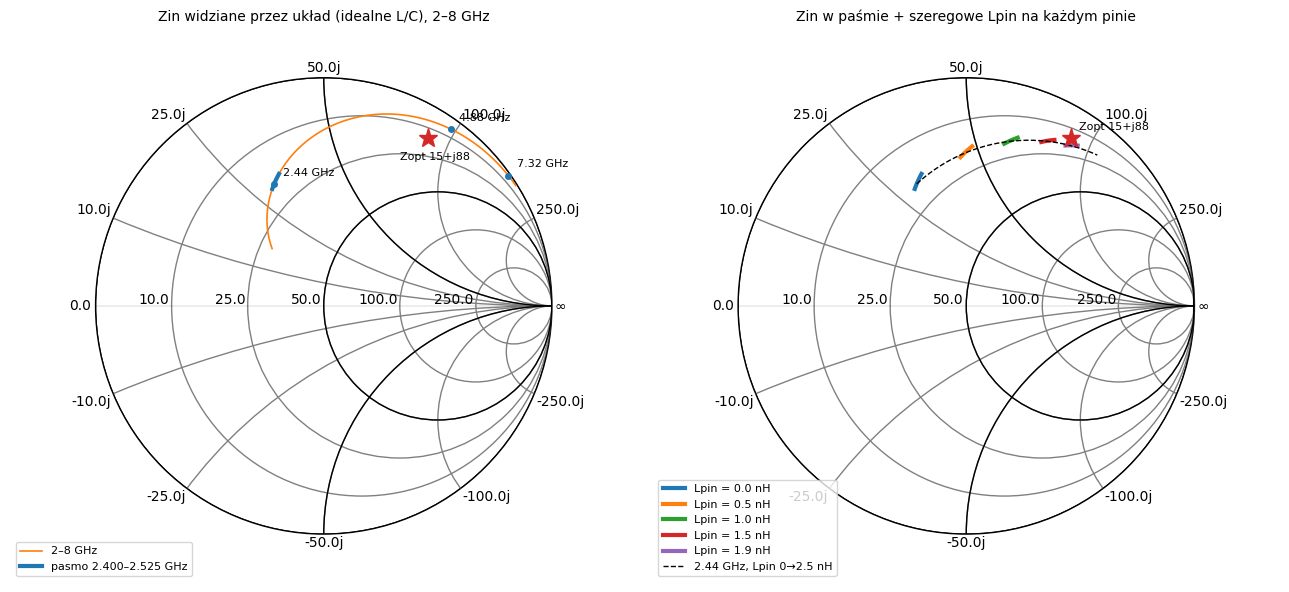

In [17]:
f = freq.f
w = 2 * np.pi * f
band = (f >= BAND[0]) & (f <= BAND[1])
gamma50 = lambda z: (z - 50) / (z + 50)

zin = zdiff_seen_by_chip(build_circuit(NOM).network)


def smith_axes(ax, title):
    rf.plotting.smith(ax=ax, chart_type='z', draw_labels=True, ref_imm=50)
    ax.set_title(title, fontsize=10)


def mark(ax, z, txt, off=(6, 6), **kw):
    g = gamma50(z)
    ax.plot(g.real, g.imag, **kw)
    ax.annotate(txt, (g.real, g.imag), textcoords='offset points', xytext=off, fontsize=8)


fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))

# --- lewy: wartości z noty
smith_axes(ax[0], 'Zin widziane przez układ (idealne L/C), 2–8 GHz')
g = gamma50(zin)
ax[0].plot(g.real, g.imag, lw=1.2, c='C1', label='2–8 GHz')
ax[0].plot(g[band].real, g[band].imag, lw=3, c='C0', label='pasmo 2.400–2.525 GHz')
for fx in (2.44e9, 4.88e9, 7.32e9):
    i = np.argmin(abs(f - fx))
    mark(ax[0], zin[i], f'{fx/1e9:.2f} GHz', marker='o', c='C0', ms=4)
mark(ax[0], ZOPT, 'Zopt 15+j88', (-20, -16), marker='*', c='C3', ms=14)
ax[0].legend(loc='lower left', fontsize=8)

# --- prawy: hipoteza Lpin
smith_axes(ax[1], 'Zin w paśmie + szeregowe Lpin na każdym pinie')
for k, Lp in enumerate((0, 0.5e-9, 1.0e-9, 1.5e-9, 1.9e-9)):
    gz = gamma50(zin[band] + 2j * w[band] * Lp)
    ax[1].plot(gz.real, gz.imag, lw=3, c=f'C{k}', label=f'Lpin = {Lp*1e9:.1f} nH')
i = np.argmin(abs(f - 2.44e9))
gt = gamma50(zin[i] + 2j * w[i] * np.linspace(0, 2.5e-9, 200))
ax[1].plot(gt.real, gt.imag, ls='--', c='k', lw=1, label='2.44 GHz, Lpin 0→2.5 nH')
mark(ax[1], ZOPT, 'Zopt 15+j88', (6, 6), marker='*', c='C3', ms=14)
ax[1].legend(loc='lower left', fontsize=8)

plt.tight_layout()
plt.show()

## ETAP 6: SWR względem Zopt

$$SWR = \frac{1+|\Gamma|}{1-|\Gamma|}, \qquad \Gamma = \frac{Z_{in}-Z_{opt}}{Z_{in}+Z_{opt}^*}$$

Po stronie układu odniesieniem jest **zespolone** Zopt, więc to SWR „mocowy” (power-wave), czyli miara odległości od optimum, a nie klasyczny SWR na linii 50 Ω.
Typowe kryterium projektowe: **SWR < 2** (|Γ| < 0,33, strata niedopasowania ≈ 0,5 dB).

Lpin = 0.0 nH:  SWR w paśmie 13.41 … 13.91
Lpin = 0.5 nH:  SWR w paśmie  7.72 …  8.55
Lpin = 1.0 nH:  SWR w paśmie  3.85 …  4.69
Lpin = 1.5 nH:  SWR w paśmie  1.64 …  2.27
Lpin = 1.9 nH:  SWR w paśmie  1.26 …  1.42


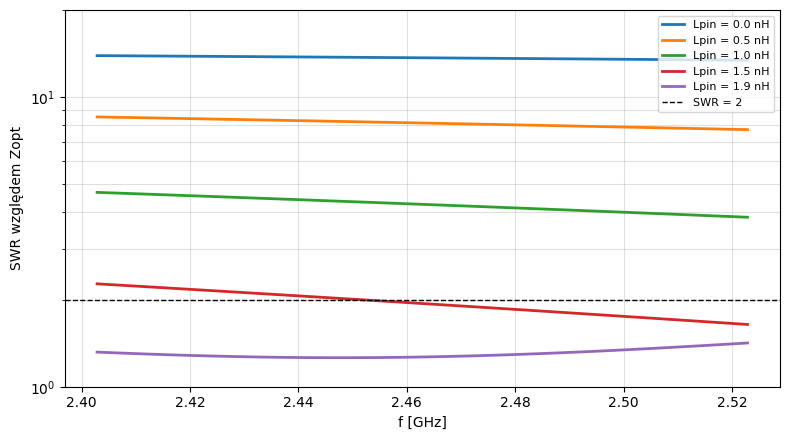

In [18]:
def swr(zin, zopt=ZOPT):
    gm, _ = mismatch(zin, zopt)
    g = np.abs(gm)
    return (1 + g) / (1 - g)


fig, ax = plt.subplots(figsize=(8, 4.5))
fb = f[band] / 1e9
for k, Lp in enumerate((0, 0.5e-9, 1.0e-9, 1.5e-9, 1.9e-9)):
    s = swr(zin + 2j * w * Lp)
    ax.plot(fb, s[band], c=f'C{k}', lw=2, label=f'Lpin = {Lp*1e9:.1f} nH')
    print(f'Lpin = {Lp*1e9:.1f} nH:  SWR w paśmie {s[band].min():5.2f} … {s[band].max():5.2f}')
ax.axhline(2, ls='--', c='k', lw=1, label='SWR = 2')
ax.set_yscale('log'); ax.set_ylim(1, 20)
ax.set_xlabel('f [GHz]'); ax.set_ylabel('SWR względem Zopt')
ax.grid(True, which='both', alpha=0.4); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## ETAP 7: Tolerancja na efekty pasożytnicze

**Dlaczego nie mierzymy już względem Zopt:** nie wiemy, gdzie leży płaszczyzna odniesienia 15+j88 (etap 5), a płytka Nordica też miała pasożyty (ESL, Q, pady), które były częścią dopasowania. Porównanie bezwzględne z Zopt mieszałoby te niewiadome.

**Podejście względne:** budujemy **płytkę referencyjną** = wartości z BOM + typowe pasożyty (`PAR_REF`), czyli przybliżenie tego, co miał Nordic. Liczymy $Z_{ref}(f)$ i pytamy: **o ile twoja płytka odchyla się od referencji?**

$$\Gamma_{rel} = \frac{Z_{in}-Z_{ref}}{Z_{in}+Z_{ref}^*}, \qquad SWR_{rel} = \frac{1+|\Gamma_{rel}|}{1-|\Gamma_{rel}|}$$

SWR_rel = 1 oznacza „zachowuje się jak referencja”. Kryterium SWR_rel < 2 = odchylenie, które przy dopasowanej referencji kosztowałoby ok. 0,5 dB. Szeregowa indukcyjność obudowy (hipoteza LPKG) prawie się tu skraca, bo dodaje tę samą reaktancję do $Z_{in}$ i $Z_{ref}$.

Modelowane pasożyty (każdy element jest teraz impedancją zależną od częstotliwości, `Circuit.SeriesImpedance`):

| Symbol | Co to jest | Typowy zakres (do weryfikacji z kartą katalogową / stackupem) |
|---|---|---|
| `Lx` | dodatkowa ścieżka szeregowo na ANT1 i ANT2 | 0–1,5 nH (rząd 0,5–1 nH na mm wąskiej ścieżki nad odległą masą) |
| `Cpad` | pojemność padu + ścieżki do masy w węzłach A, B, M, OUT | 0–0,5 pF |
| `ESL` | indukcyjność własna małych kondensatorów 0402 (C4, C5, C6) | 0,2–0,4 nH |
| `LC3` | indukcyjność gałęzi C3 (ESL + pady + przelotka do masy) | 0,2–1 nH |
| `Q` | dobroć cewek na 2,4 GHz, strata R = ωL/Q | 20–60 (∞ = ideał) |

Rezonans własny cewek (SRF) pojawi się w etapie z plikami S2P producenta.

In [19]:
PAR0    = dict(Lx=0.0, Cpad=0.0,     ESL=0.0,    LC3=0.0,    Q=np.inf)  # idealne elementy
PAR_REF = dict(Lx=0.0, Cpad=0.1e-12, ESL=0.3e-9, LC3=0.3e-9, Q=40)      # założona płytka referencyjna


def build_circuit_par(v, p):
    # Sieć jak w build_circuit, ale z pasożytami p (słownik jak PAR0).
    def Z(name, z):                      # dowolna impedancja Z(f) jako dwuwrotnik
        return Circuit.SeriesImpedance(freq, z * np.ones_like(w), name, Z0)

    def L(name, val):                    # cewka ze stratą R = wL/Q
        return Z(name, 1j * w * val + (w * val / p['Q'] if np.isfinite(p['Q']) else 0))

    def C(name, val, esl):               # kondensator z indukcyjnością szeregową
        return Z(name, 1 / (1j * w * val) + 1j * w * esl)

    L1, L2, L3 = L('L1', v['L1']), L('L2', v['L2']), L('L3', v['L3'])
    C3 = C('C3', v['C3'], p['LC3'])
    C4, C5, C6 = (C(n, v[n], p['ESL']) for n in ('C4', 'C5', 'C6'))
    Ls1 = Z('Ls1', 1j * w * p['Lx'])               # dodatkowa ścieżka ponad referencję, ANT1
    Ls2 = Z('Ls2', 1j * w * p['Lx'])               # dodatkowa ścieżka ponad referencję, ANT2
    # pojemności padów (żeby uniknąć dzielenia przez 0 przy Cpad=0 -> bardzo duża impedancja)
    cp = max(p['Cpad'], 1e-18)
    CpA, CpB, CpM, CpO = (Z(n, 1 / (1j * w * cp)) for n in ('CpA', 'CpB', 'CpM', 'CpO'))

    P1 = Circuit.Port(freq, 'P_ANT2', Z0)
    P2 = Circuit.Port(freq, 'P_ANT1', Z0)
    P3 = Circuit.Port(freq, 'P_OUT', Z0)
    G = [Circuit.Ground(freq, f'g{k}', Z0) for k in range(8)]

    cnx = [
        [(P1, 0), (Ls2, 0)],                               # pin ANT2
        [(P2, 0), (Ls1, 0)],                               # pin ANT1
        [(Ls2, 1), (L1, 0), (L3, 0), (CpA, 0)],            # węzeł A
        [(Ls1, 1), (L1, 1), (L2, 0), (CpB, 0)],            # węzeł B
        [(L2, 1), (C3, 0), (C4, 0)],                       # węzeł D (VDD_PA)
        [(L3, 1), (C5, 0), (CpM, 0)],                      # węzeł M
        [(C5, 1), (C6, 0), (CpO, 0), (P3, 0)],             # węzeł OUT
        [(C3, 1), (G[0], 0)], [(C4, 1), (G[1], 0)], [(C6, 1), (G[2], 0)],
        [(CpA, 1), (G[3], 0)], [(CpB, 1), (G[4], 0)], [(CpM, 1), (G[5], 0)], [(CpO, 1), (G[6], 0)],
    ]
    return Circuit(cnx)


def zin_par(v=NOM, p=PAR0):
    return zdiff_seen_by_chip(build_circuit_par(v, p).network)


def swr_rel(z, zref):
    g = np.abs((z - zref) / (z + np.conj(zref)))
    return (1 + g) / (1 - g)


# kontrola: bez pasożytów nowy model = model z etapu 1
assert np.max(np.abs(zin_par(NOM, PAR0) - zin)) < 0.01   # różnica < 0.01 Ω

ZREF = zin_par(NOM, PAR_REF)
i244 = np.argmin(abs(f - 2.44e9))
print(f'Idealne elementy  : Zin(2.44 GHz) = {zin[i244]:.1f} Ω')
print(f'Płytka referencyjna: Zref(2.44 GHz) = {ZREF[i244]:.1f} Ω')

Idealne elementy  : Zin(2.44 GHz) = 18.9+30.2j Ω
Płytka referencyjna: Zref(2.44 GHz) = 12.5+39.6j Ω


### 7a. Wrażliwość: każdy pasożyt osobno

Każdy pasożyt zmieniamy osobno (reszta jak w `PAR_REF`) i patrzymy na **najgorszy SWR_rel w paśmie**. Pionowa kropkowana linia = wartość referencyjna. Tam, gdzie krzywa przecina SWR_rel = 2, kończy się twój **budżet na odchylenie od referencji**.

Lx [nH] (dodatkowa ścieżka)   : SWR_rel ≤ 2 dla zakresu 0.00 … 0.25   (referencja 0.00, siatka co 0.025)
Cpad [pF]                     : SWR_rel ≤ 2 dla zakresu 0.00 … 0.24   (referencja 0.10, siatka co 0.01)
ESL C4/C5/C6 [nH]             : SWR_rel ≤ 2 dla zakresu 0.10 … 0.46   (referencja 0.30, siatka co 0.0125)
LC3 [nH]                      : SWR_rel ≤ 2 dla zakresu 0.00 … 0.40   (referencja 0.30, siatka co 0.025)
Q cewek                       : SWR_rel ≤ 2 dla zakresu 10.00 … 200.00   (referencja 40.00, siatka co 5)


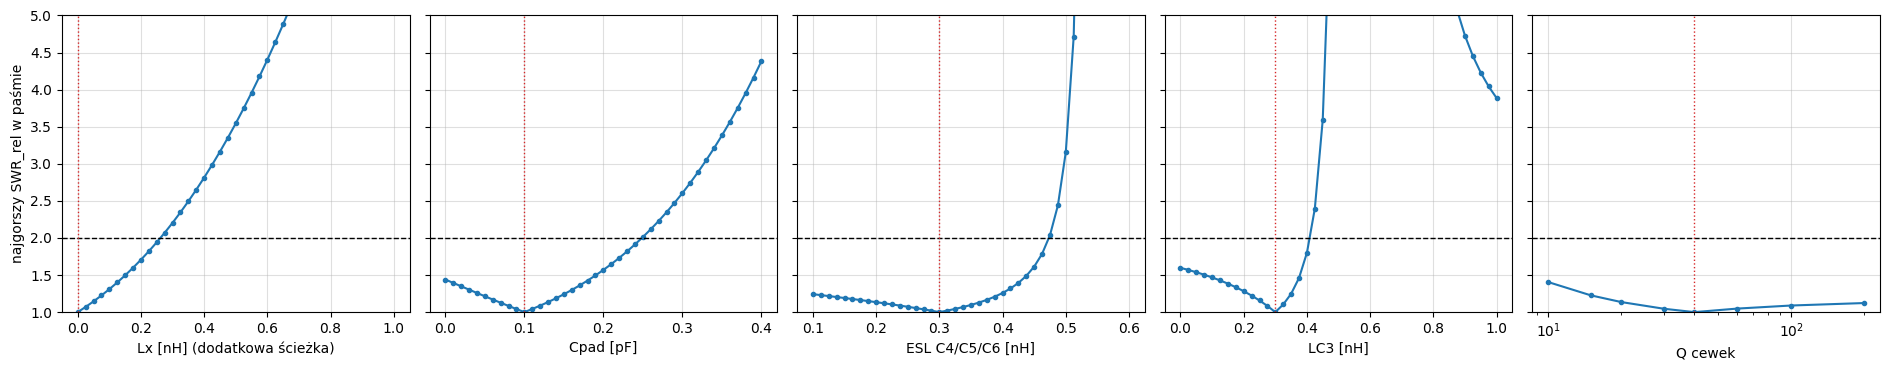

In [20]:
SWEEPS = {
    'Lx [nH] (dodatkowa ścieżka)': ('Lx',   np.linspace(0, 1.0e-9, 41), 1e9),
    'Cpad [pF]':                   ('Cpad', np.linspace(0, 0.4e-12, 41), 1e12),
    'ESL C4/C5/C6 [nH]':           ('ESL',  np.linspace(0.1e-9, 0.6e-9, 41), 1e9),
    'LC3 [nH]':                    ('LC3',  np.linspace(0.0, 1.0e-9, 41), 1e9),
    'Q cewek':                     ('Q',    np.array([10, 15, 20, 30, 40, 60, 100, 200]), 1),
}

fig, axs = plt.subplots(1, 5, figsize=(19, 3.8), sharey=True)
for ax, (label, (key, vals, scale)) in zip(axs, SWEEPS.items()):
    worst = []
    for x in vals:
        p = dict(PAR_REF); p[key] = x
        worst.append(swr_rel(zin_par(NOM, p), ZREF)[band].max())
    worst = np.array(worst)
    xs = vals * scale
    ax.plot(xs, worst, 'o-', ms=3)
    ax.axhline(2, ls='--', c='k', lw=1)
    ax.axvline(PAR_REF[key] * scale, ls=':', c='C3', lw=1)
    ax.set_xlabel(label); ax.grid(True, alpha=0.4)
    if key == 'Q':
        ax.set_xscale('log')
    ok = xs[worst <= 2]
    print(f'{label:30s}: SWR_rel ≤ 2 dla zakresu {ok.min():.2f} … {ok.max():.2f}'
          f'   (referencja {PAR_REF[key]*scale:.2f}, siatka co {xs[1]-xs[0]:.3g})')
axs[0].set_ylabel('najgorszy SWR_rel w paśmie'); axs[0].set_ylim(1, 5)
plt.tight_layout(); plt.show()

### 7b. Monte Carlo: tolerancje elementów + pasożyty jednocześnie

Każde losowanie to jedna „płytka”: wartości L/C losowane w tolerancji z BOM (rozkład jednostajny), pasożyty losowane wokół referencji w zakresach poniżej. Wynik: chmura punktów na wykresie Smitha przy 2,44 GHz (z okręgiem SWR_rel = 2 wokół Zref) i rozkład najgorszego SWR_rel w paśmie.
**Zakresy `MC_PAR` to założenia:** zawęzisz je, kiedy będziesz znał stackup i geometrię.

Uzysk (najgorszy SWR_rel w paśmie < 2): 59.2 %
Mediana: 1.73,  95. percentyl: 10.94


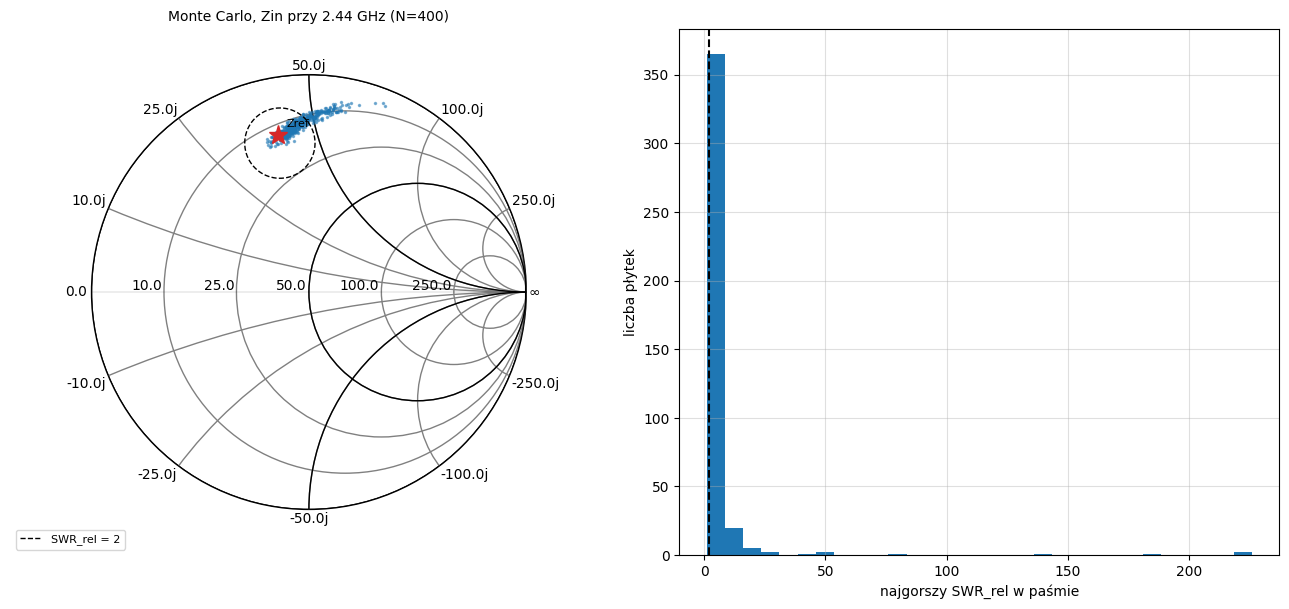

In [21]:
rng = np.random.default_rng(1)
N = 400

MC_PAR = dict(Lx=(0, 0.2e-9), Cpad=(0.07e-12, 0.13e-12), ESL=(0.25e-9, 0.35e-9),
              LC3=(0.2e-9, 0.5e-9), Q=(30, 50))
TOL_ALL = dict(TOL, C3=('rel', 0.10))


def random_board():
    v = dict(NOM)
    for name, (kind, t) in TOL_ALL.items():
        d = rng.uniform(-1, 1)
        v[name] = v[name] * (1 + d * t) if kind == 'rel' else v[name] + d * t
    p = {k: rng.uniform(*r) for k, r in MC_PAR.items()}
    return v, p


pts, worst = [], []
for _ in range(N):
    v, p = random_board()
    z = zin_par(v, p)
    pts.append(z[i244])
    worst.append(swr_rel(z, ZREF)[band].max())
pts, worst = np.array(pts), np.array(worst)

print(f'Uzysk (najgorszy SWR_rel w paśmie < 2): {100*np.mean(worst < 2):.1f} %')
print(f'Mediana: {np.median(worst):.2f},  95. percentyl: {np.percentile(worst, 95):.2f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
smith_axes(ax[0], f'Monte Carlo, Zin przy 2.44 GHz (N={N})')
g = gamma50(pts)
ax[0].plot(g.real, g.imag, '.', ms=3, alpha=0.5)
mark(ax[0], ZREF[i244], 'Zref', (6, 6), marker='*', c='C3', ms=14)
# okrąg SWR_rel = 2 wokół Zref (punkty o |Γ_rel| = 1/3)
phi = np.linspace(0, 2*np.pi, 400)
gm_c = (1/3) * np.exp(1j * phi)
zr = ZREF[i244]
z_c = (zr + gm_c * np.conj(zr)) / (1 - gm_c)              # odwrócenie wzoru na Γ
gc = gamma50(z_c)
ax[0].plot(gc.real, gc.imag, 'k--', lw=1, label='SWR_rel = 2')
ax[0].legend(loc='lower left', fontsize=8)

ax[1].hist(worst, bins=30)
ax[1].axvline(2, ls='--', c='k')
ax[1].set_xlabel('najgorszy SWR_rel w paśmie'); ax[1].set_ylabel('liczba płytek')
ax[1].grid(True, alpha=0.4)
plt.tight_layout(); plt.show()

### 7c. Diagnoza: masa w.cz. w węźle D (VDD_PA)

C3 (2,2 nF) ma rezonans własny rzędu setek MHz, więc na 2,4 GHz zachowuje się jak **cewka** (swoje ESL + pady + przelotka). C4 (4,7 pF) jest wciąż **pojemnościowy**. Cewka równolegle z kondensatorem = **antyrezonans**: na tej częstotliwości węzeł D przestaje być masą dla w.cz.

$$f_{ar} \approx \frac{1}{2\pi\sqrt{C_4\,(L_{C3}+ESL_{C4})}}$$

Poniżej |Z_D| (impedancja węzła D do masy) dla kilku wartości indukcyjności gałęzi C3. Chcesz, żeby w paśmie była **mała** i żeby antyrezonans leżał daleko od 2,4–2,5 GHz. Dołek przy ok. 4,2 GHz to rezonans szeregowy samego C4 z jego ESL (tam C4 jest najlepszą masą).

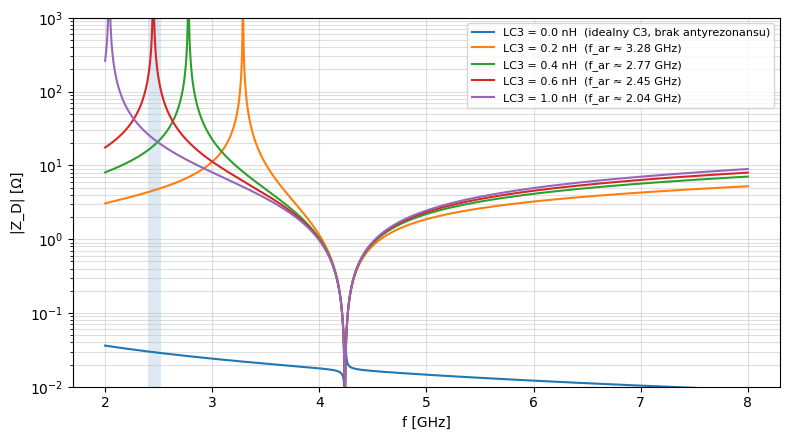

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for LC3 in (0.0, 0.2e-9, 0.4e-9, 0.6e-9, 1.0e-9):
    z_c3 = 1 / (1j * w * NOM['C3']) + 1j * w * LC3
    z_c4 = 1 / (1j * w * NOM['C4']) + 1j * w * PAR_REF['ESL']
    z_d = z_c3 * z_c4 / (z_c3 + z_c4)
    f_ar = 1 / (2 * np.pi * np.sqrt(NOM['C4'] * (LC3 + PAR_REF['ESL'])))
    txt = f'f_ar ≈ {f_ar/1e9:.2f} GHz' if LC3 > 0 else 'idealny C3, brak antyrezonansu'
    ax.semilogy(f / 1e9, np.abs(z_d), label=f'LC3 = {LC3*1e9:.1f} nH  ({txt})')
ax.axvspan(BAND[0]/1e9, BAND[1]/1e9, alpha=0.15)
ax.set_xlabel('f [GHz]'); ax.set_ylabel('|Z_D| [Ω]'); ax.set_ylim(0.01, 1e3)
ax.grid(True, which='both', alpha=0.4); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()